# **Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# **Load the Dataset**

In [2]:
# Load dataset
df = pd.read_csv('/content/spam_mail_dataset.csv')

# Display first 5 rows
df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

Dataset shape: (5572, 2)

Column names:
Index(['Category', 'Message'], dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Message   5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


# **Remove Duplicate Messages**

In [4]:
print("Number of duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Number of duplicate rows: 415
Dataset shape after removing duplicates: (5157, 2)


# **Examine Spam/Ham Distribution**

In [6]:
print(df["Category"].value_counts())

Category
ham     4516
spam     641
Name: count, dtype: int64


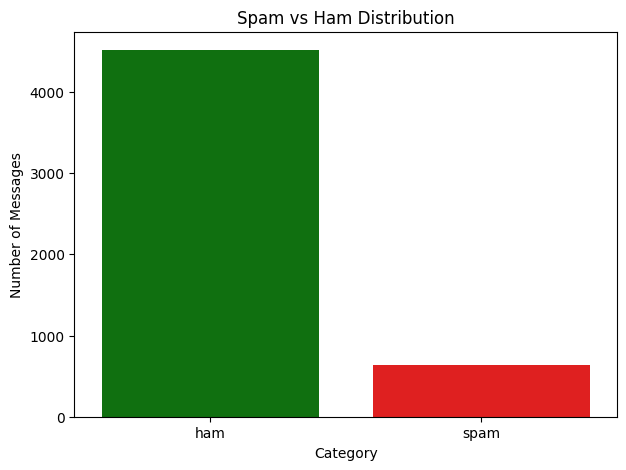

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Category",
    hue="Category",
    palette={"ham": "green", "spam": "red"},
    legend=False
)

plt.title("Spam vs Ham Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Messages")
plt.show()

In [10]:
print(
    df["Category"].value_counts(normalize=True).mul(100).round(2)
)

Category
ham     87.57
spam    12.43
Name: proportion, dtype: float64


# **Convert Spam/Ham into Numerical Labels**

In [12]:
df["label"] = df["Category"].map({
    "ham": 0,
    "spam": 1
})

df.head()

,Category,Message,label
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


# **Basic Text Preprocessing**

In [13]:
import re

def clean_text(text):
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove special characters
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [15]:
df["clean_message"] = df["Message"].apply(clean_text)

df[["Message", "clean_message"]].head()

,Message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


# **Split Dataset into Training and Testing Data**

In [16]:
X = df["clean_message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4125
Testing samples: 1032


# **Convert Text into TF-IDF Features**

In [17]:
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (4125, 5555)
Testing TF-IDF shape: (1032, 5555)


# **Training & Evaluating a Naive Bayes Model**

In [18]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

MultinomialNB()

In [19]:
y_pred_nb = nb_model.predict(X_test_tfidf)

**Evaluate**

In [20]:
print("Naive Bayes Performance")
print("-" * 40)

print("Accuracy :", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall   :", recall_score(y_test, y_pred_nb))
print("F1 Score :", f1_score(y_test, y_pred_nb))

Naive Bayes Performance
----------------------------------------
Accuracy : 0.9651162790697675
Precision: 1.0
Recall   : 0.71875
F1 Score : 0.8363636363636363


In [21]:
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=["Ham", "Spam"]
))

              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       904
        Spam       1.00      0.72      0.84       128

    accuracy                           0.97      1032
   macro avg       0.98      0.86      0.91      1032
weighted avg       0.97      0.97      0.96      1032



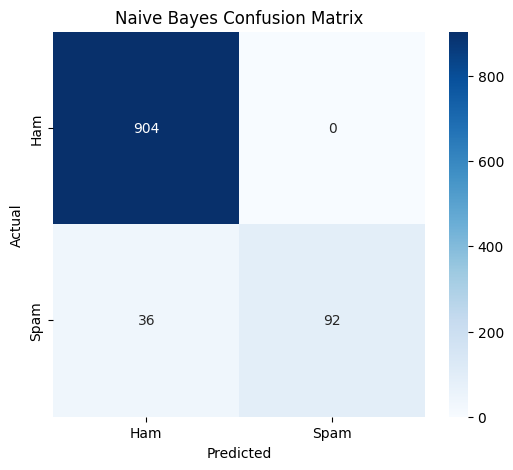

In [22]:
cm = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# **Training & Evaluating Logistic Regression**

In [23]:
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)

**Evaluate**

In [24]:
print("Logistic Regression Performance")
print("-" * 40)

print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1 Score :", f1_score(y_test, y_pred_lr))

Logistic Regression Performance
----------------------------------------
Accuracy : 0.9728682170542635
Precision: 0.8968253968253969
Recall   : 0.8828125
F1 Score : 0.889763779527559


In [25]:
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Ham", "Spam"]
))

              precision    recall  f1-score   support

         Ham       0.98      0.99      0.98       904
        Spam       0.90      0.88      0.89       128

    accuracy                           0.97      1032
   macro avg       0.94      0.93      0.94      1032
weighted avg       0.97      0.97      0.97      1032



# **Training & Evaluating Linear SVM**

In [26]:
svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

**Evaluate**

In [27]:
print("Linear SVM Performance")
print("-" * 40)

print("Accuracy :", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall   :", recall_score(y_test, y_pred_svm))
print("F1 Score :", f1_score(y_test, y_pred_svm))

Linear SVM Performance
----------------------------------------
Accuracy : 0.9757751937984496
Precision: 0.9401709401709402
Recall   : 0.859375
F1 Score : 0.8979591836734694


In [28]:
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["Ham", "Spam"]
))

              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       904
        Spam       0.94      0.86      0.90       128

    accuracy                           0.98      1032
   macro avg       0.96      0.93      0.94      1032
weighted avg       0.98      0.98      0.98      1032



# **Comparing All Models**

In [29]:
results = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "Logistic Regression",
        "Linear SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svm)
    ],
    "Precision": [
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_svm)
    ],
    "Recall": [
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_svm)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_svm)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.965116,1.000000,0.718750,0.836364
1,Logistic Regression,0.972868,0.896825,0.882812,0.889764
2,Linear SVM,0.975775,0.940171,0.859375,0.897959


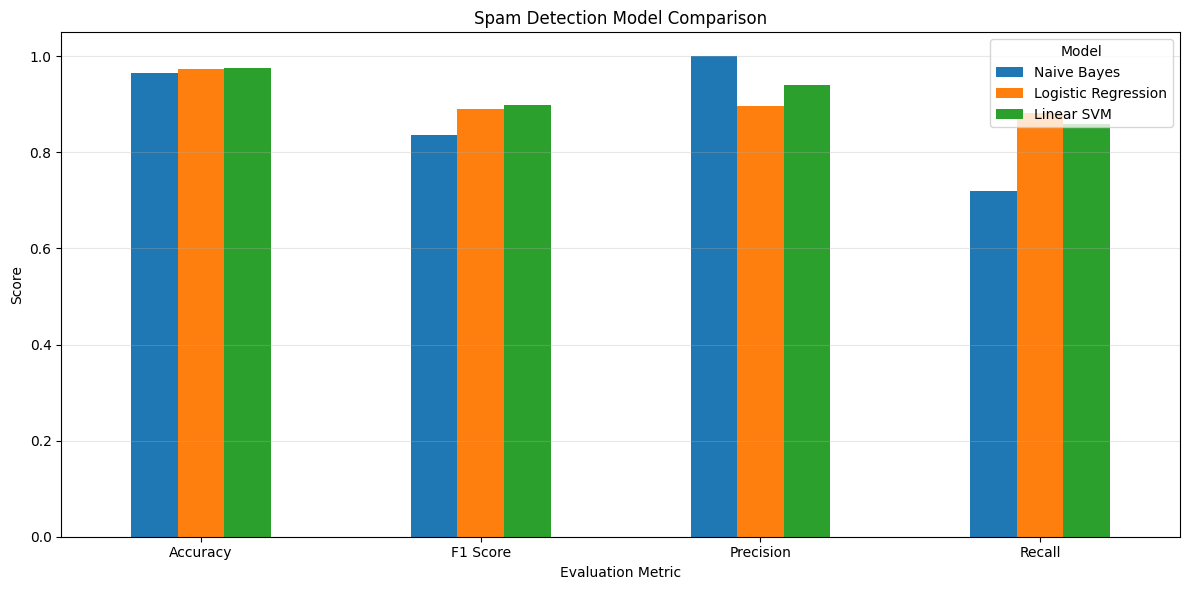

In [37]:
import matplotlib.pyplot as plt

results.set_index("Model")[["Accuracy", "F1 Score", "Precision", "Recall"]].T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Spam Detection Model Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Model")

plt.tight_layout()
plt.show()

# **Selecting the Best Model**

In [31]:
best_model_name = results.loc[
    results["F1 Score"].idxmax(),
    "Model"
]

print("Best Model:", best_model_name)

Best Model: Linear SVM


In [32]:
models = {
    "Naive Bayes": nb_model,
    "Logistic Regression": lr_model,
    "Linear SVM": svm_model
}

best_model = models[best_model_name]

print("Selected model:", best_model)

Selected model: LinearSVC(class_weight='balanced', random_state=42)


# **Testing the Model with a New Message**

In [33]:
def predict_spam(message):
    """
    Predict whether a message is spam or ham.
    """

    # Clean message
    cleaned_message = clean_text(message)

    # Convert to TF-IDF
    message_tfidf = tfidf.transform([cleaned_message])

    # Prediction
    prediction = best_model.predict(message_tfidf)[0]

    if prediction == 1:
        return "SPAM"
    else:
        return "HAM"

In [34]:
message = """
Congratulations! You have won a $1,000 prize.
Click the link to claim your reward now!
"""

result = predict_spam(message)

print("Message:", message)
print("Prediction:", result)

Message: 
Congratulations! You have won a $1,000 prize.
Click the link to claim your reward now!

Prediction: SPAM


In [35]:
message = """
Hi John,

Can you please send me the project report before tomorrow's meeting?

Thanks.
"""

print("Prediction:", predict_spam(message))

Prediction: HAM
